In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv(r"C:\Users\User\Downloads\archive (7).zip")

print("First 5 rows of the dataset:")
print(df.head())

print("\nDataset shape:")
print(df.shape)


First 5 rows of the dataset:
   gender race/ethnicity parental level of education         lunch  \
0  female        group B           bachelor's degree      standard   
1  female        group C                some college      standard   
2  female        group B             master's degree      standard   
3    male        group A          associate's degree  free/reduced   
4    male        group C                some college      standard   

  test preparation course  math score  reading score  writing score  
0                    none          72             72             74  
1               completed          69             90             88  
2                    none          90             95             93  
3                    none          47             57             44  
4                    none          76             78             75  

Dataset shape:
(1000, 8)


In [2]:
data=df["math score"].dropna()
print("\nNumber of math score values:",len(data))


Number of math score values: 1000


In [3]:
print ("\nIQR METHOD ")


IQR METHOD 


In [4]:
# Calculate Q1 (25th percentile)
Q1 = data.quantile(0.25)

Q3 = data.quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR

upper_limit = Q3 + 1.5 * IQR

print("\nIQR METHOD")
print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)


IQR METHOD
Q1: 57.0
Q3: 77.0
IQR: 20.0
Lower limit: 27.0
Upper limit: 107.0


In [6]:
# Find IQR outliers
iqr_outliers = df[
    (df["math score"] < lower_limit) | (df["math score"] > upper_limit)
]
print("Number of IQR outliers:", len(iqr_outliers))

Number of IQR outliers: 8


In [13]:
mean = data.mean()
std = data.std()
df["Z-score"] = (df["math score"] - mean) / std
z_outliers = df[abs(df["Z-score"]) > 3]
print("\nZ-score method")
print("\nmean",mean)
print("standard devation:",std)
print("number of Z-scores outliers:",len(z_outliers))


Z-score method

mean 66.089
standard devation: 15.163080096009468
number of Z-scores outliers: 4


In [22]:
print("\nIQR OUTLIERS")
if len(iqr_outliers) > 0:
  print(iqr_outliers[["math score"]])
else:
  print("No IQR outliers found.")



IQR OUTLIERS
     math score
17           18
59            0
145          22
338          24
466          26
787          19
842          23
980           8


In [24]:
print("\nZ-SCORE OUTLIERS")

if len(z_outliers) > 0:
    print(z_outliers[["math score", "Z-score"]])
else:
    print("No Z-score outliers found")




Z-SCORE OUTLIERS
     math score   Z-score
17           18 -3.171453
59            0 -4.358547
787          19 -3.105504
980           8 -3.830950


In [25]:
df["math score_treated"] = df["math score"].clip(lower=lower_limit, upper=upper_limit)
print("Treatment method: Capping using IQR limits")
print("\nBEFORE TREATMENT")
print(df["math score"].describe())
print("\nAFTER TREATMENT")
print(df["math score_treated"].describe())

Treatment method: Capping using IQR limits

BEFORE TREATMENT
count    1000.00000
mean       66.08900
std        15.16308
min         0.00000
25%        57.00000
50%        66.00000
75%        77.00000
max       100.00000
Name: math score, dtype: float64

AFTER TREATMENT
count    1000.000000
mean       66.165000
std        14.922414
min        27.000000
25%        57.000000
50%        66.000000
75%        77.000000
max       100.000000
Name: math score_treated, dtype: float64


In [31]:
Comparison = df[["math score", "math score_treated"]]
print(Comparison.head(20))

    math score  math score_treated
0           72                  72
1           69                  69
2           90                  90
3           47                  47
4           76                  76
5           71                  71
6           88                  88
7           40                  40
8           64                  64
9           38                  38
10          58                  58
11          40                  40
12          65                  65
13          78                  78
14          50                  50
15          69                  69
16          88                  88
17          18                  27
18          46                  46
19          54                  54


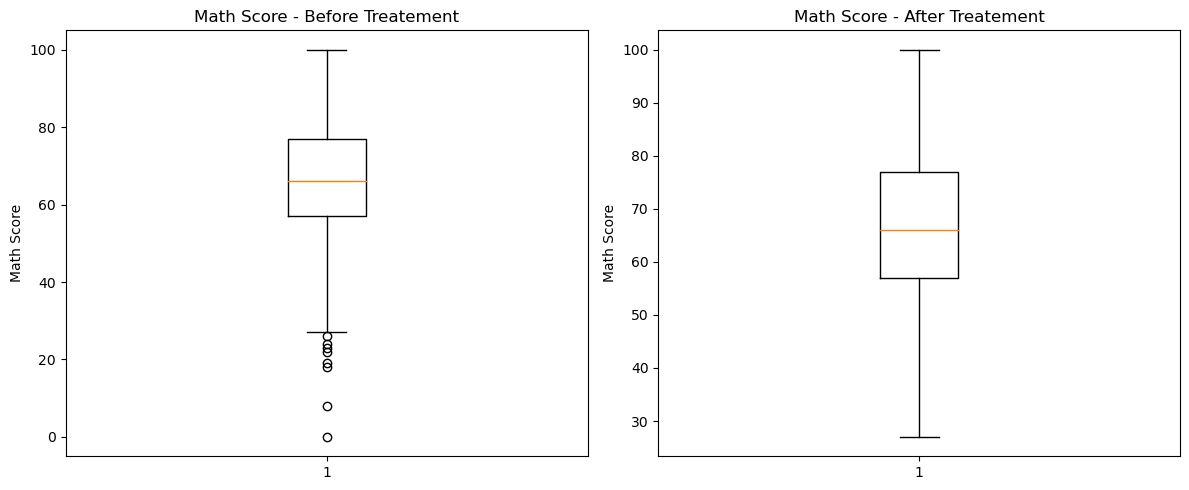

In [37]:
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.boxplot(df["math score"].dropna())
plt.title("Math Score - Before Treatement")
plt.ylabel("Math Score")
plt.subplot(1,2,2)
plt.boxplot(df["math score_treated"].dropna())
plt.title("Math Score - After Treatement")
plt.ylabel("Math Score")
plt.tight_layout()
plt.show()

Text(0, 0.5, 'Math Score')

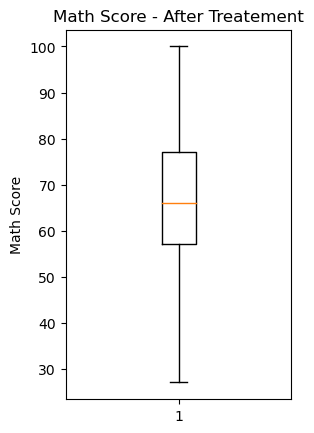